# Use case: ERA5-Land monthly averages over Europe

Earth Data Hub offers an innovative and super-efficient way to access data.

Here we present how to best access the service with a dataset that is not huge by climate standards, but is still much larger than the memory of a laptop: the ERA5-Land monthly averages.

## Setup the environment

**If you haven't done it already, follow the [Getting started notebook](./00-getting-started.ipynb) to setup your environment and DestinE credentials.**

## Analyse 30 years of ERA5-Land monthly averages over Europe

Our use case is to look at how the precipitation changed over Europe in the last decades.

We will be using the [ERA5-Land monthly dataset](https://earthdatahub.destine.eu/collections/era5/datasets/era5-land-monthly) that contains monthly averages of 60 variables from 1950 to present. Every 3D variable is about 24GiB in size and the whole dataset is about 1.2TiB.

The dataset is stored in Zarr chunks of 10 years x 20° latitude x 20° longitude, that is 120 x 200 x 200 values.

The best practice for downloading data from the Earth Data Hub comprise the following steps:
1. open the dataset using the code snippet found on the [ERA5-Land dataset page](https://earthdatahub.destine.eu/collections/era5/datasets/era5-land-monthly)
2. select the variable
3. select the area of interest
4. select the time interval of interest
5. download the data to memory (with `.compute()`)
6. compute the result in memory

### Open the dataset

The following assumes you set up your EDH API key in your _netrc_ file.

In [1]:
import xarray as xr

era5_land_monthly_dataset = xr.open_dataset(
    "https://data.earthdatahub.destine.eu/era5/era5-land-monthly-v0.zarr",
    storage_options={"client_kwargs": {"trust_env": True}},
    chunks={},
    engine="zarr",
)
era5_land_monthly_dataset

<xarray.Dataset> Size: 1TB
Dimensions:     (valid_time: 921, latitude: 1801, longitude: 3600)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2026-09-01
  * latitude    (latitude) float64 14kB 90.0 89.9 89.8 ... -89.8 -89.9 -90.0
  * longitude   (longitude) float64 29kB 0.0 0.1 0.2 0.3 ... 359.7 359.8 359.9
Data variables: (12/60)
    asn         (valid_time, latitude, longitude) float32 24GB dask.array<chunksize=(120, 200, 200), meta=np.ndarray>
    cl          (latitude, longitude) float32 26MB dask.array<chunksize=(200, 200), meta=np.ndarray>
    cvh         (latitude, longitude) float32 26MB dask.array<chunksize=(200, 200), meta=np.ndarray>
    cvl         (latitude, longitude) float32 26MB dask.array<chunksize=(200, 200), meta=np.ndarray>
    d2m         (valid_time, latitude, longitude) float32 24GB dask.array<chunksize=(120, 200, 200), meta=np.ndarray>
    dl          (latitude, longitude) float32 26MB dask.array<chunksize=(200, 200), meta=np.ndarray>
    ...          ...
    tsn         (valid_time, latitude, longitude) float32 24GB dask.array<chunksize=(120, 200, 200), meta=np.ndarray>
    tvh         (latitude, longitude) float32 26MB dask.array<chunksize=(200, 200), meta=np.ndarray>
    tvl         (latitude, longitude) float32 26MB dask.array<chunksize=(200, 200), meta=np.ndarray>
    u10         (valid_time, latitude, longitude) float32 24GB dask.array<chunksize=(120, 200, 200), meta=np.ndarray>
    v10         (valid_time, latitude, longitude) float32 24GB dask.array<chunksize=(120, 200, 200), meta=np.ndarray>
    z           (latitude, longitude) float32 26MB dask.array<chunksize=(200, 200), meta=np.ndarray>
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-22T17:02 GRIB to CDM+CF via cfgrib-0.9.1...

### Select and prepare the variable

Note that all operation are lazy, that is are not applied to the whole 1.2TiB of data, but are just recorded for later use. Download and computations are only done when requested.

We pick the total precipitation `tp`.

In [2]:
tp_world = era5_land_monthly_dataset.tp
tp_world

<xarray.DataArray 'tp' (valid_time: 921, latitude: 1801, longitude: 3600)> Size: 24GB
dask.array<open_dataset-tp, shape=(921, 1801, 3600), dtype=float32, chunksize=(120, 200, 200), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2026-09-01
  * latitude    (latitude) float64 14kB 90.0 89.9 89.8 ... -89.8 -89.9 -90.0
  * longitude   (longitude) float64 29kB 0.0 0.1 0.2 0.3 ... 359.7 359.8 359.9
Attributes: (12/31)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      6483600
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_gridType:                            regular_ll
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m
    long_name:                                Total precipitation
    units:                                    m
    standard_name:                            unknown
    last_ingested_valid_time_index:           920

### Select the area of interest

We are interested in Europe.

Two details of this dataset matter here:
* the latitude coordinate is descending, from 90 to -90,
* the longitude coordinate goes from 0 to 360, so Europe is split between the two ends of the axis and the two parts must be read and concatenated.

We take a window from 70.1°N to 30.1°N and from 20°W to 40°E; the bounds are chosen on the Zarr chunk boundaries (every 20°) so we download almost only the data we use.

In [3]:
aoi_selection = {
    "latitude": slice(
        70.1, 30.1
    ),  # NOTE: ERA5-Land has a descending latitude coordinate
}

tp_aoi = xr.concat(
    [
        tp_world.sel(longitude=slice(340, 360), **aoi_selection),
        tp_world.sel(longitude=slice(0, 40), **aoi_selection),
    ],
    dim="longitude",
)
# Use longitudes from -180 to 180 for a more familiar map
tp_aoi = tp_aoi.assign_coords(longitude=(tp_aoi.longitude + 180) % 360 - 180)
tp_aoi

<xarray.DataArray 'tp' (valid_time: 921, latitude: 400, longitude: 600)> Size: 884MB
dask.array<concatenate, shape=(921, 400, 600), dtype=float32, chunksize=(120, 200, 200), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2026-09-01
  * latitude    (latitude) float64 3kB 70.0 69.9 69.8 69.7 ... 30.3 30.2 30.1
  * longitude   (longitude) float64 5kB -20.0 -19.9 -19.8 ... 39.7 39.8 39.9
Attributes: (12/31)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      6483600
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_gridType:                            regular_ll
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m
    long_name:                                Total precipitation
    units:                                    m
    standard_name:                            unknown
    last_ingested_valid_time_index:           920

Note that the data size is now much smaller, we went from 24GiB for the global variable to 884MiB of our area of interest for the whole 1950-2026 period.

We plot one month over Italy, a single chunk, to see what the data looks like:

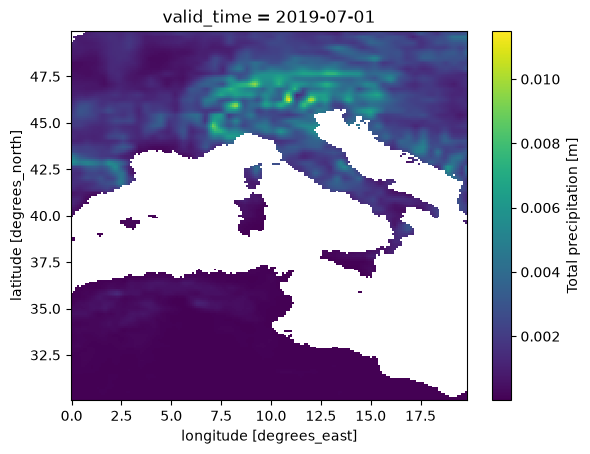

In [4]:
tp_italy = tp_aoi.sel(latitude=slice(50, 30.1), longitude=slice(0, 19.9))
tp_italy.sel(valid_time="2019-07-01").plot()

### Select the time interval of interest

We take the 30 year period from 1990 to 2019, aligned on the 10 year time chunks, and we finally have a definition of the data we want to download.

In [5]:
tp_aoi_toi = tp_aoi.sel(valid_time=slice("1990", "2019"))
tp_aoi_toi

<xarray.DataArray 'tp' (valid_time: 360, latitude: 400, longitude: 600)> Size: 346MB
dask.array<getitem, shape=(360, 400, 600), dtype=float32, chunksize=(120, 200, 200), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 3kB 1990-01-01 ... 2019-12-01
  * latitude    (latitude) float64 3kB 70.0 69.9 69.8 69.7 ... 30.3 30.2 30.1
  * longitude   (longitude) float64 5kB -20.0 -19.9 -19.8 ... 39.7 39.8 39.9
Attributes: (12/31)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      6483600
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_gridType:                            regular_ll
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m
    long_name:                                Total precipitation
    units:                                    m
    standard_name:                            unknown
    last_ingested_valid_time_index:           920

From the representation above we learn a few things:
1. the uncompressed data to be downloaded, e.g. 346MiB (compression depends on the dataset and the variable)
2. the number of chunks to be downloaded, e.g. 18, that is 2 latitude chunks x 3 longitude chunks x 3 time chunks

### Download the data to memory

Finally we are ready to download only the data that we are interested in, in memory.

The best practice is to call the `.compute()` method load the data into a numpy array in memory.

**This operation is the slow one, it can take a couple of minutes.**

It depends on the download speed of your internet connection and on the load on the Earth Data Hub. The closer you are to the data the faster it is, and this is one of the reason the EDH is best suited to be used from within the DestinE platform.

In [6]:
%%time

tp_aoi_toi_data = tp_aoi_toi.compute()

CPU times: user 3.2 s, sys: 1.18 s, total: 4.38 s
Wall time: 1min 3s


### Perform any computation

#### Prepare the raw data

In the ERA5-Land monthly averages, accumulated variables like `tp` hold the average daily accumulation in metres. We convert it to the monthly total in millimetres.

In [7]:
days_in_month = tp_aoi_toi_data.valid_time.dt.days_in_month
tp_aoi_toi_data_mm = tp_aoi_toi_data * 1000 * days_in_month
tp_aoi_toi_data_mm.attrs["units"] = "mm"
tp_aoi_toi_data_mm.attrs["long_name"] = "monthly precipitation"
tp_aoi_toi_data_mm

<xarray.DataArray (valid_time: 360, latitude: 400, longitude: 600)> Size: 691MB
array([[[        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        ...,
        [        nan,         nan,         nan, ...,  7.31937587,
          8.21599364,  9.1278553 ],
        [        nan,         nan,         nan, ...,  7.30459392,
          8.18550587,  9.06503201],
        [        nan,         nan,         nan, ...,  7.98410177,
          8.98650289, 10.0120008 ]],

       [[        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
...
        [        nan,         nan,         nan, ...,  9.45657492,
          9.67562199,  9.8374486 ],
        [        nan,         nan,         nan, ...,  9.04887915,
          9.1329217 ,  9.19371843],
        [        nan,         nan,         nan, ...,  8.8763237 ,
          9.01848078,  9.12666321]],

       [[        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        ...,
        [        nan,         nan,         nan, ...,  4.10152972,
          4.25766408,  4.37776744],
        [        nan,         nan,         nan, ...,  3.42895091,
          3.52688134,  3.61626595],
        [        nan,         nan,         nan, ...,  3.1568706 ,
          3.1735003 ,  3.14555317]]], shape=(360, 400, 600))
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 3kB 1990-01-01 ... 2019-12-01
  * latitude    (latitude) float64 3kB 70.0 69.9 69.8 69.7 ... 30.3 30.2 30.1
  * longitude   (longitude) float64 5kB -20.0 -19.9 -19.8 ... 39.7 39.8 39.9
Attributes: (12/31)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      6483600
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_gridType:                            regular_ll
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m
    long_name:                                monthly precipitation
    units:                                    mm
    standard_name:                            unknown
    last_ingested_valid_time_index:           920

#### Annual totals

Monthly data is convenient to describe the seasons, but the year to year variability of the climate is easier to read from annual totals.

`skipna=False` keeps the sea, where ERA5-Land has no data, as missing values instead of zeros.

In [8]:
%%time

tp_aoi_toi_annual = tp_aoi_toi_data_mm.groupby("valid_time.year").sum(skipna=False)
tp_aoi_toi_annual.attrs["long_name"] = "annual precipitation"
tp_aoi_toi_annual

CPU times: user 79.9 ms, sys: 85.6 ms, total: 166 ms
Wall time: 168 ms


<xarray.DataArray (year: 30, latitude: 400, longitude: 600)> Size: 58MB
array([[[         nan,          nan,          nan, ...,          nan,
                  nan,          nan],
        [         nan,          nan,          nan, ...,          nan,
                  nan,          nan],
        [         nan,          nan,          nan, ...,          nan,
                  nan,          nan],
        ...,
        [         nan,          nan,          nan, ...,  24.92439793,
          25.07522749,  25.26078897],
        [         nan,          nan,          nan, ...,  21.5028231 ,
          21.87265595,  22.23910531],
        [         nan,          nan,          nan, ...,  19.75102682,
          20.42841126,  21.15695883]],

       [[         nan,          nan,          nan, ...,          nan,
                  nan,          nan],
        [         nan,          nan,          nan, ...,          nan,
                  nan,          nan],
        [         nan,          nan,          nan, ...,          nan,
                  nan,          nan],
...
        [         nan,          nan,          nan, ..., 119.6222229 ,
         122.97250127, 126.16039609],
        [         nan,          nan,          nan, ..., 121.51340378,
         124.77888149, 127.90926342],
        [         nan,          nan,          nan, ..., 122.83895892,
         126.98248011, 130.60840761]],

       [[         nan,          nan,          nan, ...,          nan,
                  nan,          nan],
        [         nan,          nan,          nan, ...,          nan,
                  nan,          nan],
        [         nan,          nan,          nan, ...,          nan,
                  nan,          nan],
        ...,
        [         nan,          nan,          nan, ...,  77.24080462,
          77.94956345,  78.42969376],
        [         nan,          nan,          nan, ...,  81.98950667,
          81.57885302,  81.00731153],
        [         nan,          nan,          nan, ...,  80.52301261,
          81.04289178,  81.05995361]]], shape=(30, 400, 600))
Coordinates:
  * year       (year) int64 240B 1990 1991 1992 1993 ... 2016 2017 2018 2019
  * latitude   (latitude) float64 3kB 70.0 69.9 69.8 69.7 ... 30.3 30.2 30.1
  * longitude  (longitude) float64 5kB -20.0 -19.9 -19.8 ... 39.7 39.8 39.9
Attributes: (12/31)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      6483600
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_gridType:                            regular_ll
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m
    long_name:                                annual precipitation
    units:                                    mm
    standard_name:                            unknown
    last_ingested_valid_time_index:           920

#### Mean annual precipitation

The 30 year mean shows the wet Atlantic coasts and mountain ranges and the dry south.

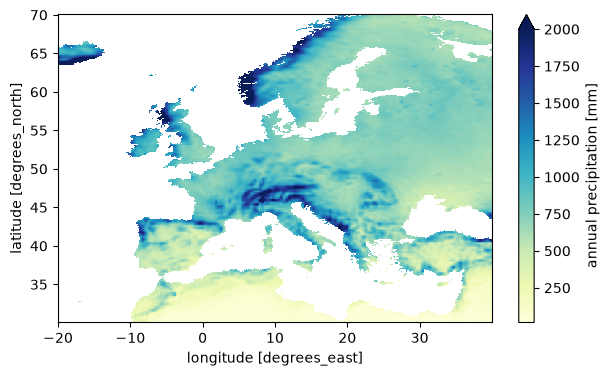

In [9]:
tp_aoi_toi_mean = tp_aoi_toi_annual.mean("year")
tp_aoi_toi_mean.plot(cmap="YlGnBu", vmax=2000, figsize=(7, 4))

#### Precipitation trend

Averaging over the whole area gives a single time series for Europe and a linear fit on it summarises the change over the period.

The simple mean over all grid points gives more weight to the high latitudes, where the grid cells are smaller; a proper area weighting would use `cos(latitude)` as weight, but for this example the simple mean is good enough.

Precipitation varies a lot from year to year, so the trend of a single 30 year period is uncertain.

In [10]:
tp_europe_annual = tp_aoi_toi_annual.mean(["latitude", "longitude"])

tp_europe_trend = tp_europe_annual.polyfit("year", 1)
tp_europe_trend = tp_europe_trend.polyfit_coefficients.sel(degree=1)

print(f"Europe mean precipitation trend: {10 * float(tp_europe_trend):.0f} mm/decade")

Europe mean precipitation trend: 7 mm/decade


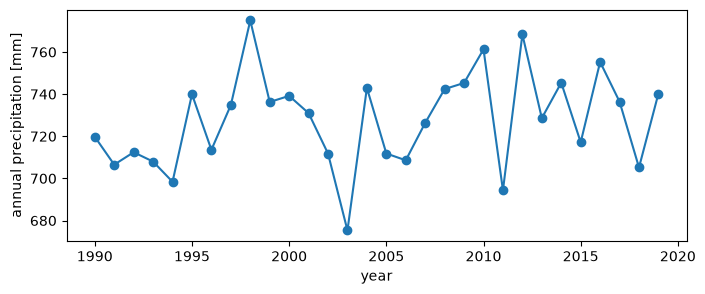

In [11]:
tp_europe_annual.plot(marker="o", figsize=(8, 3))

#### Trend map

The same linear fit applied at every grid point, divided by the mean annual precipitation, gives the trend in percent per decade, that can be compared between wet and dry regions. Over the deserts in the south of the area the mean is close to zero and the relative trend is not meaningful.

CPU times: user 336 ms, sys: 18.6 ms, total: 354 ms
Wall time: 349 ms


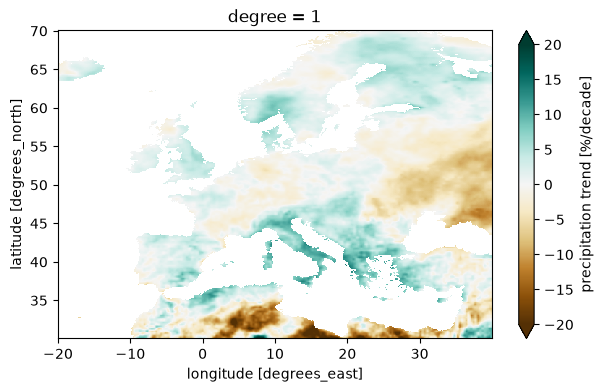

In [12]:
%%time

tp_aoi_toi_trend = tp_aoi_toi_annual.polyfit("year", 1)
tp_aoi_toi_trend = tp_aoi_toi_trend.polyfit_coefficients.sel(degree=1) * 10
tp_aoi_toi_trend = 100 * tp_aoi_toi_trend / tp_aoi_toi_mean
tp_aoi_toi_trend.attrs["units"] = "%/decade"
tp_aoi_toi_trend.attrs["long_name"] = "precipitation trend"
tp_aoi_toi_trend.plot(cmap="BrBG", vmin=-20, vmax=20, figsize=(7, 4))

### Next steps

* replace `tp` with any other variable of the dataset, e.g. the 2 metre temperature `t2m` or the volumetric soil water `swvl1`,
* replace the area and the period of interest with the ones you need, keeping in mind that the data is downloaded in chunks of 10 years x 20° x 20°.